In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

df = pd.read_csv("C:/Users/saino/Downloads/dataset.csv")
df

,study_hours,sleep_hours,phone_usage,attendance,assignment,stress,social_hours,past_grade,final_score,final_result
0,2,6,6,65,0,8,4,55,50,Fail
1,3,7,5,70,0,7,3,60,55,Fail
2,4,6,4,75,1,6,3,65,65,Pass
3,5,7,3,80,1,5,2,70,72,Pass
4,6,8,2,85,1,4,2,75,80,Pass
5,7,7,2,90,1,3,2,80,85,Pass
6,1,5,7,60,0,9,5,50,45,Fail
7,2,6,6,68,0,8,4,55,52,Fail
8,3,6,5,72,1,7,3,60,60,Fail
9,4,7,4,78,1,6,3,65,68,Pass


## KNN Classification

In [2]:
X = df.drop(["final_result", "final_score"], axis=1)
y = df["final_result"]

X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42
)

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
distances, indices = knn.kneighbors([X_test.iloc[0]])
print("3 nearest neighbors(index):", indices)
print("Distances:", distances)

Accuracy: 0.8333333333333334
3 nearest neighbors(index): [[21 14 10]]
Distances: [[2.23606798 3.60555128 3.87298335]]


C:\Users\saino\anaconda3\envs\py310\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


## Linear Regression

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

X = df.drop(["final_score", "final_result"], axis=1)
y = df["final_score"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error (MSE):", mse)

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})
print("\nModel Coefficients:")
print(coefficients)

most_important = coefficients.loc[coefficients["Coefficient"].abs().idxmax()]
print("\nMost Influential Feature:")
print(most_important)

study_index = list(X.columns).index("study_hours")
impact = model.coef_[study_index] * 2
print("\nImpact if study_hours increase by 2:", impact)

Mean Squared Error (MSE): 2.9493049412984464

Model Coefficients:
        Feature  Coefficient
0   study_hours    -1.012069
1   sleep_hours     0.900219
2   phone_usage     0.702072
3    attendance     1.025777
4    assignment     5.349025
5        stress     1.012069
6  social_hours     0.815843
7    past_grade     0.751145

Most Influential Feature:
Feature        assignment
Coefficient      5.349025
Name: 4, dtype: object

Impact if study_hours increase by 2: -2.0241373141662167


## K-Means Clustering

C:\Users\saino\anaconda3\envs\py310\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(



Clusters added:
   study_hours  sleep_hours  phone_usage  attendance  assignment  stress  \
0            2            6            6          65           0       8   
1            3            7            5          70           0       7   
2            4            6            4          75           1       6   
3            5            7            3          80           1       5   
4            6            8            2          85           1       4   

   social_hours  past_grade  final_score final_result  cluster  
0             4          55           50         Fail        2  
1             3          60           55         Fail        1  
2             3          65           65         Pass        1  
3             2          70           72         Pass        0  
4             2          75           80         Pass        0  


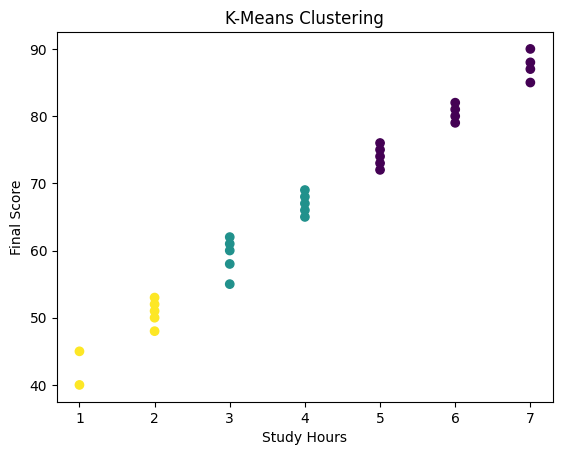


Cluster Analysis:
         study_hours  sleep_hours  phone_usage  attendance  assignment  \
cluster                                                                  
0           5.923077     7.461538     2.153846   85.307692         1.0   
1           3.500000     6.300000     4.500000   73.200000         0.9   
2           1.714286     5.428571     6.285714   64.571429         0.0   

           stress  social_hours  past_grade  final_score  
cluster                                                   
0        4.076923      1.769231   76.307692    80.153846  
1        6.500000      3.000000   63.300000    63.100000  
2        8.285714      4.285714   54.285714    48.428571  


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

X_cluster = df.drop(["final_score", "final_result"], axis=1)

kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X_cluster)

df["cluster"] = kmeans.labels_

print("\nClusters added:")
print(df.head())

plt.figure()
plt.scatter(
    df["study_hours"],
    df["final_score"],
    c=df["cluster"],
    cmap="viridis"
)
plt.xlabel("Study Hours")
plt.ylabel("Final Score")
plt.title("K-Means Clustering")
plt.show()

cluster_analysis = df.groupby("cluster").mean(numeric_only=True)
print("\nCluster Analysis:")
print(cluster_analysis)